# Cycle 0 — Understanding HotpotQA

**Goal:** understand the data well enough that every later design decision (chunking, Top-K, retriever, metrics, agent design) is justified by something we measured here.

**Data:** HotpotQA *distractor* setting, validation split (7,405 questions). We use a fixed random sample of **2,000 questions** (seed 42) as the development pool; all later evaluation subsets are drawn from it.

Sections:
1. What one example looks like
2. Questions and answers
3. Context paragraphs (→ chunking, Top-K, cost)
4. Supporting facts (where the proof lives)
5. Lexical overlap — why multi-hop retrieval is hard
6. Evidence chains (worked examples)
7. Building the search corpus
8. Takeaways → design decisions

In [1]:
import random
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.data import load_corpus, load_dev_pool, paragraph_text
from src.evaluate import normalize_answer

FIG_DIR = PROJECT_ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

pool = load_dev_pool()
corpus = load_corpus(pool)
print(f"Development pool: {len(pool):,} questions | Corpus: {len(corpus):,} unique paragraphs")

Development pool: 2,000 questions | Corpus: 19,260 unique paragraphs


## 1. What one example looks like

Each example has:
- `question`, `answer`
- `type`: **bridge** (find entity A, then use it to find the answer) or **comparison** (look up two entities and compare them)
- `level`: easy / medium / hard — every validation question is labeled *hard*, so we don't analyze it
- `context`: 10 Wikipedia paragraphs (title + sentences) — **2 gold** paragraphs that contain the evidence and **8 distractors** chosen to look relevant
- `supporting_facts`: the exact `(paragraph title, sentence index)` pairs that prove the answer

Below, gold paragraphs are tagged and supporting sentences are marked with `>>`. Distractors show only their first sentence.

In [2]:
def show_example(ex, width=160):
    sup = {(sf["title"], sf["sent_id"]) for sf in ex["supporting_facts"]}
    print(f"QUESTION: {ex['question']}")
    print(f"ANSWER:   {ex['answer']}    | type: {ex['type']} | level: {ex['level']}")
    print(f"SUPPORTING FACTS: {sorted(sup)}\n")
    for p in ex["paragraphs"]:
        is_gold = p["title"] in ex["gold_titles"]
        print(f"[{'GOLD' if is_gold else 'distractor'}] {p['title']}")
        sentences = p["sentences"] if is_gold else p["sentences"][:1]
        for i, s in enumerate(sentences):
            mark = ">>" if (p["title"], i) in sup else "  "
            print(f"   {mark} ({i}) {s[:width]}")
    print()


show_example(pool[0])

QUESTION: In what year was the university where Sergei Aleksandrovich Tokarev was a professor founded?
ANSWER:   1755    | type: bridge | level: hard
SUPPORTING FACTS: [('Moscow State University', 3), ('Sergei Aleksandrovich Tokarev', 0)]

[GOLD] Moscow State University
      (0) Lomonosov Moscow State University (MSU; Russian: Московский государственный университет имени М.
      (1) В.
      (2) Ломоносова , often abbreviated МГУ) is a coeducational and public research university located in Moscow, Russia.
   >> (3) It was founded on January 25, 1755 by Mikhail Lomonosov.
      (4) MSU was renamed after Lomonosov in 1940 and was then known as "Lomonosov University".
      (5) It also houses the tallest educational building in the world.
      (6) It is rated among the universities with the best reputation in the world.
      (7) Its current rector is Viktor Sadovnichiy.
[distractor] Sergei Roshchin
      (0) Sergei Aleksandrovich Roshchin (Russian: Серге́й Александрович Рощин ; born 

**What this example shows**
- It's a **bridge** question: *Tokarev → (was a professor at) Moscow State University → founded 1755*. The answer lives in the **Moscow State University** paragraph, but the question never mentions Moscow — you only learn that name after reading the Tokarev paragraph. That's the essence of multi-hop.
- The distractors are **7 other people named "Sergei Aleksandrovich"**. They share many words with the question, so a naive keyword or embedding search can easily rank them above the real evidence.
- The data has **noise**: the Russian abbreviation "М. В." was wrongly split into separate sentences. This is one reason we retrieve whole paragraphs, not individual sentences.

## 2. Questions and answers

What kinds of questions and answers are there? This drives the **answer prompt** (how short the answer must be) and the **metrics** (exact match is harsh on long answers; yes/no answers can be guessed).

Answer categories come from simple rules (yes/no, date/year, number, capitalized named entity, other), so they're approximate.

In [3]:
MONTHS = r"\b(january|february|march|april|may|june|july|august|september|october|november|december)\b"
NUMBER_WORDS = r"^(one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|hundred|thousand|million)\b"
MINOR_WORDS = {"of", "the", "and", "de", "in", "for", "a", "on", "to", "&"}


def answer_category(answer):
    low = answer.strip().lower()
    if low in ("yes", "no"):
        return "yes/no"
    if re.search(MONTHS, low) or re.search(r"\b1[0-9]\d{2}s?\b|\b20\d{2}s?\b", low):
        return "date/year"
    if re.search(r"\d", low) or re.search(NUMBER_WORDS, low):
        return "number/quantity"
    words = [w for w in answer.split() if w.lower() not in MINOR_WORDS]
    if words and all(w[0].isupper() for w in words if w[0].isalpha()):
        return "named entity"
    return "other phrase"


qdf = pd.DataFrame(
    {
        "id": [e["id"] for e in pool],
        "type": [e["type"] for e in pool],
        "question": [e["question"] for e in pool],
        "answer": [e["answer"] for e in pool],
    }
)
qdf["q_words"] = qdf.question.str.split().str.len()
qdf["a_words"] = qdf.answer.str.split().str.len()
qdf["a_category"] = qdf.answer.map(answer_category)

print("Question types:")
display(pd.DataFrame({"count": qdf.type.value_counts(), "share": qdf.type.value_counts(normalize=True).round(3)}))

print("Answer category by question type (share of each type):")
display(pd.crosstab(qdf.a_category, qdf.type, normalize="columns").round(3))

print("Answer length (words):")
display(qdf.groupby("type").a_words.describe(percentiles=[0.5, 0.9, 0.99]).round(1))
print(f"Answers with <= 3 words: {(qdf.a_words <= 3).mean():.1%}")

print("\nQuestion length (words):")
display(qdf.groupby("type").q_words.describe(percentiles=[0.5, 0.9]).round(1))

print("Random answer examples per category:")
display(qdf.groupby("a_category").sample(3, random_state=0)[["a_category", "type", "question", "answer"]])

Question types:


,count,share
type,,
bridge,1604,0.802
comparison,396,0.198


Answer category by question type (share of each type):


type,bridge,comparison
a_category,,
date/year,0.111,0.008
named entity,0.636,0.510
number/quantity,0.089,0.013
other phrase,0.164,0.164
yes/no,0.000,0.306


Answer length (words):


,count,mean,std,min,50%,90%,99%,max
type,,,,,,,,
bridge,1604.0,2.6,1.8,1.0,2.0,5.0,9.0,19.0
comparison,396.0,2.1,1.7,1.0,2.0,4.0,9.1,14.0


Answers with <= 3 words: 82.8%

Question length (words):


,count,mean,std,min,50%,90%,max
type,,,,,,,
bridge,1604.0,16.8,5.6,6.0,16.0,24.0,45.0
comparison,396.0,11.7,3.1,6.0,11.0,16.0,25.0


Random answer examples per category:


,a_category,type,question,answer
1006,date/year,bridge,"Orson Scott Card first published his short story ""Killing Children"" in this American science-fiction magazine whose ...",1930
120,date/year,bridge,"The 249th episode of ""The Simpsons"" was aired on what date?","November 1, 2000"
640,date/year,bridge,Peter and the Wolf was originally released as a segment of an animated anthology released to theaters on which day ?,"April 20, 1946"
1110,named entity,bridge,The Luther seal was designed for the professor of theology of what nationalty at the behest of John Frederick of Sax...,German
167,named entity,comparison,"Which film director is younger, Robert Z. Leonard or Sinclair Hill?",Sinclair Hill
505,named entity,bridge,Scott Sandelin grew up in a town in what Minnesota county?,Saint Louis County
1586,number/quantity,bridge,What is the 2010 population of the village at which Smith Haven Mall was located?,"11,163"
108,number/quantity,bridge,"What type of license is the open source roguelike video game video released 2012, in which a subset of it's pricing ...",GNU GPLv3
1507,number/quantity,bridge,"How many pornographic films did the actress, who co-hosted the 29th AVN Awards with Dave Attell and Sunny Leone, app...",281
1794,other phrase,bridge,"What is Opry Mills in Nashville, Tennessee?",super-regional shopping mall


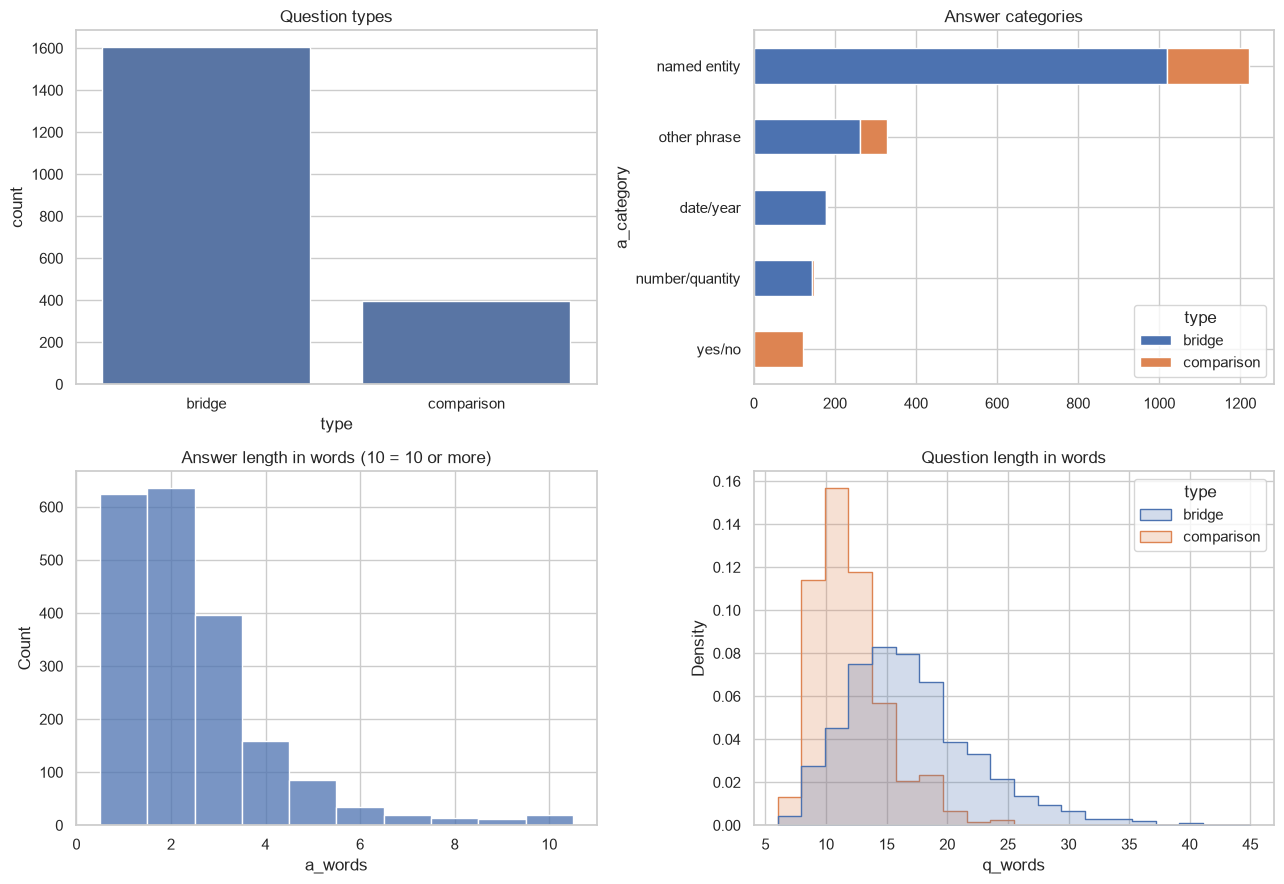

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(data=qdf, x="type", ax=axes[0, 0])
axes[0, 0].set_title("Question types")

cat_order = qdf.a_category.value_counts().index
pd.crosstab(qdf.a_category, qdf.type).loc[cat_order].plot.barh(stacked=True, ax=axes[0, 1])
axes[0, 1].set_title("Answer categories")
axes[0, 1].invert_yaxis()

sns.histplot(qdf.a_words.clip(upper=10), discrete=True, ax=axes[1, 0])
axes[1, 0].set_title("Answer length in words (10 = 10 or more)")

sns.histplot(data=qdf, x="q_words", hue="type", binwidth=2, element="step", stat="density", common_norm=False, ax=axes[1, 1])
axes[1, 1].set_title("Question length in words")

plt.tight_layout()
plt.savefig(FIG_DIR / "eda_questions_answers.png", dpi=120)
plt.show()

**Findings**
- **80% bridge, 20% comparison.** Bridge questions dominate, so the overall score will mostly reflect how well we handle the second hop.
- **Answers are short:** median 2 words, 83% are 3 words or fewer. The answer prompt must demand a short span, otherwise exact match (EM) punishes correct but verbose answers. We report **F1** alongside EM because it gives partial credit.
- **Yes/no = 6% overall but 31% of comparison questions.** A model that always says "yes" gets some of these right for free; we'll report metrics **per question type** so this doesn't hide weaknesses.
- **Most answers are named entities** (64% of bridge answers), which favors retrieval methods that match names exactly.
- **Bridge questions are longer** (median 16 vs 11 words) because they describe the bridge entity indirectly ("the university where X was a professor").
- Gold answers are sometimes **fuller than the title**: "Dara Grace Torres", not "Dara Torres" (see Section 6). A correct model answer can still fail EM, which is another reason to track F1 and inspect failures by hand.

## 3. Context paragraphs

How big are the paragraphs? This decides **chunking** (do we need to split paragraphs?) and the **token cost of Top-K** (how many tokens each retrieved paragraph adds to the prompt).

Token counts are estimated as characters / 4, a standard rule of thumb for English text with Llama-style tokenizers.

Paragraphs per question: {2: 6, 3: 1, 4: 4, 5: 1, 6: 1, 7: 1, 9: 1, 10: 1985}

Paragraph size, gold vs distractor:


n_sentences                 n_words                     n_tokens_est                      
                  mean median  p90 max    mean median    p90   max         mean median    p90     max
kind                                                                                                 
distractor         4.4    4.0  7.0  85    94.9   84.0  159.0  1378        150.5  133.2  250.8  2069.2
gold               3.3    3.0  5.1  14    69.2   62.0  118.0   290        110.4  100.5  185.5   443.5

Estimated prompt size for Top-K retrieved paragraphs:


,est_prompt_tokens
K,
2,435
5,862
10,1574
20,2999


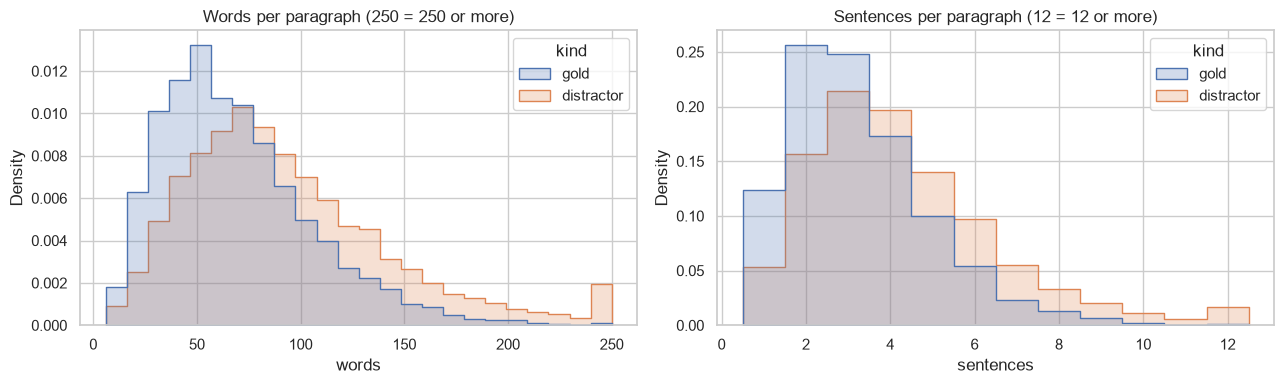

In [5]:
para_rows = []
for e in pool:
    for p in e["paragraphs"]:
        text = paragraph_text(p)
        para_rows.append(
            {
                "qid": e["id"],
                "kind": "gold" if p["title"] in e["gold_titles"] else "distractor",
                "n_sentences": len(p["sentences"]),
                "n_words": len(text.split()),
                "n_tokens_est": len(f"{p['title']}: {text}") / 4,
            }
        )
pdf = pd.DataFrame(para_rows)

print("Paragraphs per question:", dict(sorted(Counter(pdf.groupby("qid").size()).items())))
print("\nParagraph size, gold vs distractor:")
display(
    pdf.groupby("kind")[["n_sentences", "n_words", "n_tokens_est"]]
    .agg(["mean", "median", lambda s: s.quantile(0.9), "max"])
    .rename(columns={"<lambda_0>": "p90"})
    .round(1)
)

mean_tokens = pdf.n_tokens_est.mean()
PROMPT_OVERHEAD = 150  # instructions + question
print("Estimated prompt size for Top-K retrieved paragraphs:")
display(
    pd.DataFrame(
        {"K": k, "est_prompt_tokens": round(PROMPT_OVERHEAD + k * mean_tokens)} for k in [2, 5, 10, 20]
    ).set_index("K")
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=pdf, x=pdf.n_words.clip(upper=250), hue="kind", binwidth=10, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set_title("Words per paragraph (250 = 250 or more)")
axes[0].set_xlabel("words")
sns.histplot(data=pdf, x=pdf.n_sentences.clip(upper=12), hue="kind", discrete=True, stat="density", common_norm=False, element="step", ax=axes[1])
axes[1].set_title("Sentences per paragraph (12 = 12 or more)")
axes[1].set_xlabel("sentences")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_paragraphs.png", dpi=120)
plt.show()

**Findings**
- 1,985 of 2,000 questions have the full 10 paragraphs; 15 have fewer (the dataset is slightly irregular, not a bug in our loading).
- Paragraphs are **small**: gold paragraphs have a median of 3 sentences / 62 words (~100 tokens); 90% are under ~190 tokens. Only a few distractors are very long (max ~2,000 tokens).
- **Decision — chunking:** one paragraph = one chunk, with the title prepended. Paragraphs are already short, self-contained units about one entity; splitting them would separate facts from the entity name they describe (e.g. "It was founded in 1755" loses "Moscow State University").
- **Decision — Top-K cost:** each paragraph adds ~140 tokens on average. K=5 costs ~860 prompt tokens, K=10 ~1,600, K=20 ~3,000. All fit comfortably in the LLM context; the real trade-off is noise and per-call cost, which we'll choose from the recall@K curve in Cycle 1.
- Distractors are longer than gold paragraphs (95 vs 69 words on average). Longer paragraphs contain more words and can accidentally match more queries — BM25's length normalization matters here.

## 4. Supporting facts — where the proof lives

- How many supporting sentences does a question need?
- Where in a paragraph is the evidence (first sentence? later?)
- Does the answer appear **word-for-word** in a gold paragraph (extractive), and in **which** one?

For bridge questions, the gold paragraph that contains the answer is the **second hop**; the other is the **first hop**. We use this to label hops in Sections 5–6.

Supporting sentences per question:


n_supporting,2,3,4,5,6,7
questions,1377,467,128,24,3,1


Position of supporting sentences inside their paragraph:


,sentence 0,sentence 1,sentence 2,sentence 3,sentence 4+
share,0.571,0.233,0.111,0.048,0.038


How many gold paragraphs contain the exact answer string (share of each type):


type,bridge,comparison
gold_with_answer,,
0 gold paragraph(s),0.006,0.000
1 gold paragraph(s),0.751,0.606
2 gold paragraph(s),0.243,0.088
yes/no answer,0.000,0.306


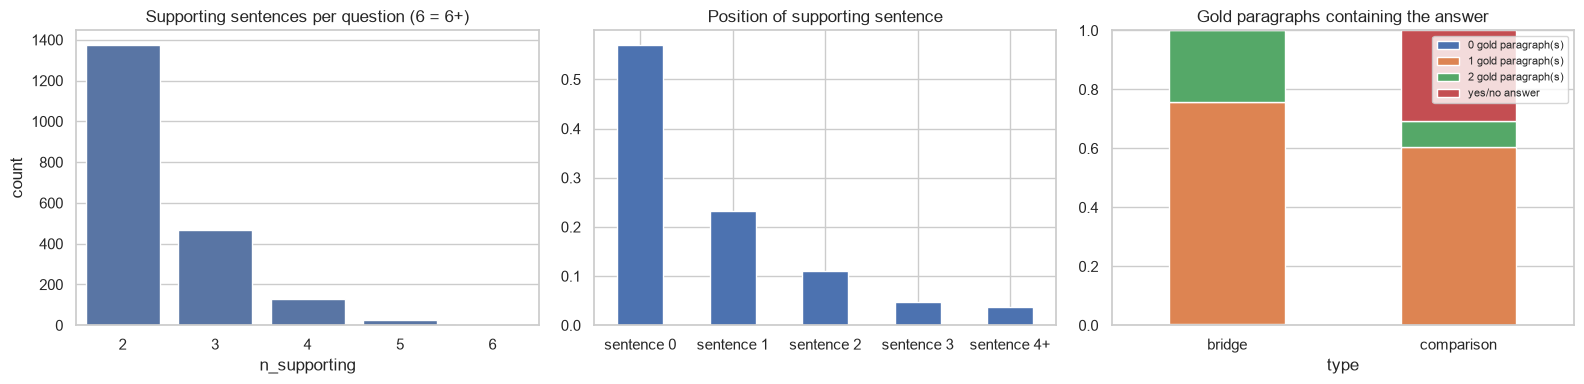

In [6]:
def contains_answer(paragraph, answer):
    ans = normalize_answer(answer)
    text = normalize_answer(paragraph["title"] + " " + paragraph_text(paragraph))
    return bool(ans) and f" {ans} " in f" {text} "


sf_rows, positions = [], []
for e in pool:
    is_yes_no = normalize_answer(e["answer"]) in ("yes", "no")
    gold = [p for p in e["paragraphs"] if p["title"] in e["gold_titles"]]
    with_answer = [p["title"] for p in gold if not is_yes_no and contains_answer(p, e["answer"])]
    positions += [sf["sent_id"] for sf in e["supporting_facts"]]
    sf_rows.append(
        {
            "type": e["type"],
            "n_supporting": len(e["supporting_facts"]),
            "gold_with_answer": "yes/no answer" if is_yes_no else f"{len(with_answer)} gold paragraph(s)",
        }
    )
sfdf = pd.DataFrame(sf_rows)

print("Supporting sentences per question:")
display(sfdf.n_supporting.value_counts().sort_index().to_frame("questions").T)

pos = pd.Series(positions).clip(upper=4).value_counts(normalize=True).sort_index().round(3)
pos.index = ["sentence 0", "sentence 1", "sentence 2", "sentence 3", "sentence 4+"]
print("Position of supporting sentences inside their paragraph:")
display(pos.to_frame("share").T)

print("How many gold paragraphs contain the exact answer string (share of each type):")
answer_location = pd.crosstab(sfdf.gold_with_answer, sfdf.type, normalize="columns").round(3)
display(answer_location)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x=sfdf.n_supporting.clip(upper=6), ax=axes[0])
axes[0].set_title("Supporting sentences per question (6 = 6+)")
pos.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Position of supporting sentence")
answer_location.T.plot.bar(stacked=True, ax=axes[2], rot=0)
axes[2].set_title("Gold paragraphs containing the answer")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_supporting_facts.png", dpi=120)
plt.show()

**Findings**
- **69% of questions need exactly 2 supporting sentences** — typically one from each gold paragraph. The task is "find two short facts and connect them", not "read long documents".
- **57% of supporting sentences are the first sentence** of their paragraph (Wikipedia first sentences define the entity: who/what/when/where). Paragraph-level retrieval therefore captures the evidence well.
- **The answer appears word-for-word in a gold paragraph for >99% of non-yes/no questions.** The task is almost fully *extractive*: if retrieval succeeds, the LLM mainly needs to pick the right span. So **retrieval quality will be the main bottleneck**, and we should measure it separately (Evidence Recall@K).
- For **75% of bridge questions, exactly one gold paragraph contains the answer** — that paragraph is the second hop. We use this to label hops in the next section. (In 24%, the answer string appears in both, so the hop order is ambiguous and we leave those out of the hop analysis.)

**Why multi-hop QA is harder than ordinary QA**

In ordinary QA (e.g. SQuAD), one passage contains everything, and the question is usually worded like that passage. In multi-hop QA:
1. **The evidence is split** across two documents; neither alone answers the question.
2. **The second document is described only indirectly** ("the university where Tokarev was a professor"). You only learn its name from the first document, so a single search can't target it reliably.
3. **Errors compound**: missing either paragraph, or connecting the wrong bridge entity, gives a wrong answer even if every other step is perfect.
4. **Distractors are adversarial**: they are chosen to look like the question, so surface similarity is misleading.

## 5. Lexical overlap — why multi-hop retrieval is hard

A retriever can only find a paragraph if it looks similar to the question. We measure, for each paragraph, the **share of the question's content words** (stopwords removed) that appear in it, and whether the paragraph's **title** (the entity name) is mentioned in the question.

We compare:
- **Hop 1** gold paragraph (bridge questions): the entity the question talks about
- **Hop 2** gold paragraph (bridge questions): the paragraph with the answer, reached through the bridge entity
- **Comparison** gold paragraphs
- **Distractors**

Hypothesis: the hop-2 paragraph shares far fewer words with the question, so a single search using only the question will often miss it.

Bridge questions with unambiguous hop labels: 1205/1604 (75%)



,paragraphs,mean_overlap,title_mentioned_in_question,beaten_by_best_distractor
group,,,,
hop 1 (gold),1205,0.557,0.614,0.311203
hop 2 (gold),1205,0.443,0.137,0.525311
comparison (gold),792,0.465,1.000,0.414141
distractor,15908,0.413,0.036,NaN


Hop-2 title appears inside the hop-1 paragraph (the 'bridge' link): 65.6%
Comparison questions that name BOTH entities: 100.0%


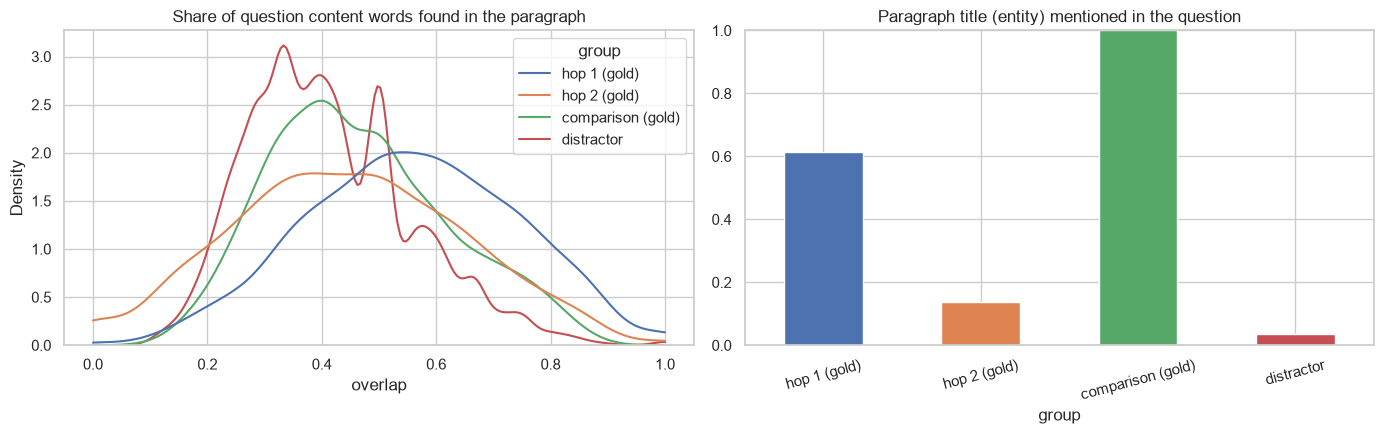

In [7]:
STOPWORDS = set(
    """a an the of in on at to for from by with and or but not is are was were be been being am
    which who whom whose what when where why how that this these those did does do has have had
    as it its his her their they them he she him we you i than then there also both either same
    other into about after before during over under between more most many much such""".split()
)


def content_words(text):
    return {w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOPWORDS and len(w) > 1}


def overlap(question, paragraph):
    q = content_words(question)
    p = content_words(paragraph["title"] + " " + paragraph_text(paragraph))
    return len(q & p) / len(q) if q else 0.0


def core_title(title):
    return re.sub(r"\s*\(.*?\)", "", title).strip().lower()


def title_in_text(title, text):
    return core_title(title) in text.lower()


def bridge_hops(ex):
    """(hop1, hop2) paragraphs for a bridge question, or None if the answer location is ambiguous."""
    gold = [p for p in ex["paragraphs"] if p["title"] in ex["gold_titles"]]
    with_answer = [p for p in gold if contains_answer(p, ex["answer"])]
    if ex["type"] != "bridge" or len(with_answer) != 1:
        return None
    hop2 = with_answer[0]
    hop1 = next(p for p in gold if p is not hop2)
    return hop1, hop2


rows = []
n_bridge = n_bridge_labeled = 0
for e in pool:
    q = e["question"]
    distractors = [p for p in e["paragraphs"] if p["title"] not in e["gold_titles"]]
    best_distractor = max((overlap(q, p) for p in distractors), default=0.0)
    for p in distractors:
        rows.append({"group": "distractor", "overlap": overlap(q, p), "title_in_q": title_in_text(p["title"], q)})
    if e["type"] == "bridge":
        n_bridge += 1
        hops = bridge_hops(e)
        if hops is None:
            continue
        n_bridge_labeled += 1
        hop1, hop2 = hops
        rows.append(
            {
                "group": "hop 1 (gold)",
                "overlap": overlap(q, hop1),
                "title_in_q": title_in_text(hop1["title"], q),
                "beaten_by_distractor": best_distractor > overlap(q, hop1),
                "bridge_link": title_in_text(hop2["title"], paragraph_text(hop1)),
            }
        )
        rows.append(
            {
                "group": "hop 2 (gold)",
                "overlap": overlap(q, hop2),
                "title_in_q": title_in_text(hop2["title"], q),
                "beaten_by_distractor": best_distractor > overlap(q, hop2),
            }
        )
    else:
        for p in e["paragraphs"]:
            if p["title"] in e["gold_titles"]:
                rows.append(
                    {
                        "group": "comparison (gold)",
                        "overlap": overlap(q, p),
                        "title_in_q": title_in_text(p["title"], q),
                        "beaten_by_distractor": best_distractor > overlap(q, p),
                    }
                )
odf = pd.DataFrame(rows)

print(f"Bridge questions with unambiguous hop labels: {n_bridge_labeled}/{n_bridge} ({n_bridge_labeled / n_bridge:.0%})\n")
group_order = ["hop 1 (gold)", "hop 2 (gold)", "comparison (gold)", "distractor"]
summary = (
    odf.groupby("group")
    .agg(
        paragraphs=("overlap", "size"),
        mean_overlap=("overlap", "mean"),
        title_mentioned_in_question=("title_in_q", "mean"),
        beaten_by_best_distractor=("beaten_by_distractor", "mean"),
    )
    .loc[group_order]
)
display(summary.round(3))

hop1_rows = odf[odf.group == "hop 1 (gold)"]
print(f"Hop-2 title appears inside the hop-1 paragraph (the 'bridge' link): {hop1_rows.bridge_link.mean():.1%}")

comp_titles = odf[odf.group == "comparison (gold)"].title_in_q.values.reshape(-1, 2)
print(f"Comparison questions that name BOTH entities: {comp_titles.all(axis=1).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.kdeplot(data=odf, x="overlap", hue="group", hue_order=group_order, common_norm=False, clip=(0, 1), ax=axes[0])
axes[0].set_title("Share of question content words found in the paragraph")
summary.title_mentioned_in_question.plot.bar(ax=axes[1], rot=15, color=sns.color_palette()[:4])
axes[1].set_title("Paragraph title (entity) mentioned in the question")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_lexical_overlap.png", dpi=120)
plt.show()

**Findings — the hypothesis is confirmed**
- **Hop-2 paragraphs look almost like distractors.** Their word overlap with the question (0.44) is barely above that of distractors (0.41), while hop-1 paragraphs are clearly higher (0.56).
- **The hop-2 entity is named in the question only 14% of the time** vs 61% for hop 1. Search engines match on names, so hop 2 is often invisible to a search that uses only the question.
- **In 53% of bridge questions, some distractor overlaps the question more than the hop-2 paragraph does** — even among just the 10 paragraphs of its own context. In our 19k-paragraph corpus it gets worse.
- **The bridge link is often explicit:** in 66% of cases the hop-2 title literally appears inside the hop-1 paragraph. So after reading hop 1, a second search for that name should find hop 2. This is precisely what an **iterative/agentic retriever** can exploit and a single-shot pipeline can't.
- **Comparison questions name both entities 100% of the time.** Their difficulty is different: the retriever must fetch *both* paragraphs, not just the more similar one. Since the names are in the question, **keyword search (BM25) should do well** on them, and a hybrid retriever should help.

**Prediction for Cycle 1:** the baseline will usually find hop 1 but miss hop 2 on bridge questions; recall on comparison questions will be higher.

## 6. Evidence chains — worked examples

For each example we lay out the chain the system must follow: **question → hop 1 fact → bridge entity → hop 2 fact → answer** (bridge), or **question → fact about entity A + fact about entity B → compare → answer** (comparison).

In [8]:
def supporting_sentences(ex, paragraph):
    ids = sorted(sf["sent_id"] for sf in ex["supporting_facts"] if sf["title"] == paragraph["title"])
    return [paragraph["sentences"][i] for i in ids if i < len(paragraph["sentences"])]


def show_chain(ex):
    print(f"QUESTION: {ex['question']}   [{ex['type']}]")
    if ex["type"] == "bridge":
        hop1, hop2 = bridge_hops(ex)
        steps = [("Hop 1", hop1), ("Hop 2", hop2)]
    else:
        gold = [p for p in ex["paragraphs"] if p["title"] in ex["gold_titles"]]
        steps = list(zip(["Entity A", "Entity B"], gold))
    for label, p in steps:
        print(f"  {label}: [{p['title']}]")
        for s in supporting_sentences(ex, p):
            print(f"      fact: {s}")
    if ex["type"] == "bridge":
        print(f"  Bridge entity: '{hop2['title']}' (named in the question? {title_in_text(hop2['title'], ex['question'])})")
    print(f"  ANSWER: {ex['answer']}\n")


rng = random.Random(7)
clean_bridge = [
    e
    for e in pool
    if (h := bridge_hops(e))
    and title_in_text(h[1]["title"], paragraph_text(h[0]))
    and not title_in_text(h[1]["title"], e["question"])
    and len(e["question"]) < 130
]
comparison = [e for e in pool if e["type"] == "comparison" and len(e["question"]) < 110]
comparison_yes_no = [e for e in comparison if e["answer"].lower() in ("yes", "no")]
comparison_entity = [e for e in comparison if e["answer"].lower() not in ("yes", "no")]

chain_examples = rng.sample(clean_bridge, 3) + [rng.choice(comparison_yes_no), rng.choice(comparison_entity)]
for ex in chain_examples:
    show_chain(ex)

QUESTION: Which American former competitive swimmer was Mitzi Kremer team mate   [bridge]
  Hop 1: [Mitzi Kremer]
      fact: Kremer received a bronze medal as a member of the third-place U.S. team in the women's 4×100-meter freestyle relay, together with teammates Mary Wayte, Dara Torres and Laura Walker.
  Hop 2: [Dara Torres]
      fact: Dara Grace Torres (born April 15, 1967) is an American former competitive swimmer who is a twelve-time Olympic medalist and former world record-holder in three events.
  Bridge entity: 'Dara Torres' (named in the question? False)
  ANSWER: Dara Grace Torres

QUESTION: In which year was the King who made the 1925 Birthday Honours born?   [bridge]
  Hop 1: [1925 Birthday Honours]
      fact: The 1925 Birthday Honours were appointments by King George V to various orders and honours to reward and highlight good works by citizens of the British Empire.
  Hop 2: [George V]
      fact: George V (George Frederick Ernest Albert; 3 June 1865 – 20 January 1936

**Evidence chains mapped explicitly**

1. *Which American former competitive swimmer was Mitzi Kremer's teammate?* (bridge)
   `Question` → **[Mitzi Kremer]** "bronze medal … with teammates Mary Wayte, **Dara Torres** and Laura Walker" → *bridge entity: Dara Torres* → **[Dara Torres]** "an American former competitive swimmer" → **Dara Grace Torres**.
   Note the hop-1 paragraph lists *three* teammates; only hop 2 tells us which one is the "American former competitive swimmer". Also: the gold answer is the full name, so the answer "Dara Torres" would fail EM but score well on F1.
2. *In which year was the King who made the 1925 Birthday Honours born?* (bridge)
   `Question` → **[1925 Birthday Honours]** "appointments by King **George V**" → *bridge: George V* → **[George V]** "born 3 June 1865" → **1865**.
3. *What province is the city where Matti Hoikka was a blacksmith and politician?* (bridge)
   `Question` → **[Matti Hoikka]** "born … in **Rovaniemi**" → *bridge: Rovaniemi* → **[Rovaniemi]** "capital of Finland's northernmost province, Lapland" → **Lapland**.
   Note the gold answer is "Finland's northernmost province, Lapland"; an LLM answering "Lapland" is right but fails EM.
4. *Are Distortion Mirrors and OK Go both considered rock bands?* (comparison, yes/no)
   `Question` → **[Distortion Mirrors]** "alternative rock band" + **[OK Go]** "American rock band" → compare: both rock → **yes**.
5. *Which director was from a country closer to Canada, J. Searle Dawley or Lionel Ngakane?* (comparison)
   `Question` → **[Lionel Ngakane]** "South African filmmaker" + **[J. Searle Dawley]** "American director" → compare using **world knowledge** (the US borders Canada) → **James Searle Dawley**.
   Not every step is in the text; the LLM must supply common-sense knowledge to finish the reasoning.

## 7. Building the search corpus

In the distractor setting each question comes with its own 10 paragraphs, and "retrieval" among 10 is too easy to be realistic. Instead we pool **all paragraphs from all 2,000 questions**, deduplicate by title, and treat that as our mini-Wikipedia. Every question must now find its 2 gold paragraphs among ~19k candidates, including the carefully chosen distractors of *other* questions.

Why not the full Wikipedia index (5M+ articles, "fullwiki" setting)? Indexing and searching it is far beyond a laptop budget, and it wouldn't change the research question — this is one of the approaches we deliberately reject.

In [9]:
gold_titles = {t for e in pool for t in e["gold_titles"]}
title_counts = Counter(p["title"] for e in pool for p in e["paragraphs"])

texts_by_title = {}
for e in pool:
    for p in e["paragraphs"]:
        texts_by_title.setdefault(p["title"], set()).add(paragraph_text(p))
conflicts = sum(len(v) > 1 for v in texts_by_title.values())

corpus_words = pd.Series([len(d["text"].split()) for d in corpus])
corpus_stats = {
    "paragraph slots in the 2,000 contexts": sum(title_counts.values()),
    "unique paragraphs (corpus size)": len(corpus),
    "gold paragraphs": len(gold_titles),
    "distractor-only paragraphs": len(corpus) - len(gold_titles),
    "paragraphs shared by 2+ questions": sum(c > 1 for c in title_counts.values()),
    "titles with differing text (kept first)": conflicts,
    "median words per paragraph": int(corpus_words.median()),
    "total words in corpus": int(corpus_words.sum()),
}
display(pd.Series(corpus_stats).to_frame("value"))
print(f"Chance that a random paragraph is one of a question's 2 gold paragraphs: 2 / {len(corpus):,} = {2 / len(corpus):.4%}")

,value
"paragraph slots in the 2,000 contexts",19908
unique paragraphs (corpus size),19260
gold paragraphs,3904
distractor-only paragraphs,15356
paragraphs shared by 2+ questions,598
titles with differing text (kept first),4
median words per paragraph,79
total words in corpus,1706255


Chance that a random paragraph is one of a question's 2 gold paragraphs: 2 / 19,260 = 0.0104%


**Findings**
- The corpus has **19,260 unique paragraphs** (~1.7M words): 3,904 gold and 15,356 distractor-only. Each question must find its 2 gold paragraphs among them — a random guess has a 0.01% chance per paragraph.
- 598 paragraphs appear in more than one question's context, which is why deduplication matters.
- Only 4 titles had slightly different text across questions — negligible; we keep the first version.
- At this size, embedding the whole corpus once takes minutes on a laptop CPU, and BM25 indexing takes seconds, so we can compare several retrievers cheaply.

## 8. Takeaways → design decisions

| Finding | Design decision |
|---|---|
| Paragraphs are short (median ~62 words gold, ~100 tokens) and self-contained | **Chunk = one paragraph, with the title prepended.** No splitting. |
| Each paragraph adds ~140 tokens; K=5 ≈ 860 prompt tokens | **Start with Top-K = 5**, then choose K from the recall@K curve (K = 2, 5, 10, 20) in Cycle 1. |
| Answer is in the gold text for >99% of non-yes/no questions | Retrieval is the main bottleneck → **measure Evidence Recall@K separately from answer quality**, and classify each error as retrieval vs reasoning. |
| Every question needs both gold paragraphs | Report **both-gold recall@K** (share of questions with both paragraphs retrieved), not just average recall. |
| Answers are short (83% ≤ 3 words); gold answers sometimes use full names | **Short-answer prompt; report both EM and F1**; count "correct but differently worded" cases in manual error analysis. |
| Yes/no = 31% of comparison questions | **Report every metric per question type** (bridge vs comparison). |
| Hop-2 paragraphs are rarely named in the question (14%) and overlap it barely more than distractors | Expect the **single-shot baseline to miss hop 2 on bridge questions** — the main motivation for iterative, agentic retrieval (Cycle 3). |
| The hop-2 title appears in the hop-1 text 66% of the time | An agent that **reads hop 1 and searches for the entity it names** should recover hop 2. |
| Comparison questions always name both entities; answers are mostly named entities | **Keyword search (BM25) and hybrid retrieval** should help, especially on comparison questions (Cycle 2 hypothesis). |
| Adversarial distractors look like the question (e.g. seven other "Sergei Aleksandrovich"s) | A **cross-encoder reranker**, which reads question and paragraph together, should separate the real match from look-alikes (Cycle 2 hypothesis). |
| Some questions need world knowledge beyond the text (e.g. which country is closer to Canada) | Some failures will come from **reasoning, not retrieval** — track them separately. |